In [38]:
import os
import pandas as pd
import trxtools.methods as ttm
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from trxtools.utils.names import cleanNames
from trxtools import metaprofiles as meta

In [39]:
gtf_path = "../references/Saccharomyces_cerevisiae.EF4.74_SGDv64_CUTandSUT_withUTRs_noEstimates_antisense_intergenic_4xlncRNAs_final.pyCheckGTFfile.output.corrected.gtf"
gtf = pd.read_csv(gtf_path, sep='\t', comment='#', header=None)
# gtf_gene_df = pd.DataFrame({
#     'gene_id': gtf[8].str.extract(r'gene_id "([^"]+)"', expand=False),
#     'biotype': gtf[1],
#     'gene_name': gtf[8].str.extract(r'gene_name "([^"]+)"', expand=False)
# })
gtf['gene_name'] = gtf[8].str.extract(r'gene_name "([^"]+)"', expand=False)
gtf['gene_id'] = gtf[8].str.extract(r'gene_id "([^"]+)"', expand=False)

## Fig 3A

In [40]:
# From Supp. Table S2
gene_list = pd.read_csv("references/fig2_cluster_5_6.tsv", sep="\t")

In [41]:
gtf_fig3 = gtf[gtf['gene_name'].isin(gene_list['gene'])]
gtf_fig3 = gtf_fig3[gtf_fig3[2].isin(['exon'])]
gtf_fig3['length'] = gtf_fig3[4] - gtf_fig3[3]
bed_fig3 = gtf_fig3[[0, 3, 4, 'gene_name', 5, 6]]

# Filter for length between 500 and 2800
gtf_fig3_lensorted = gtf_fig3[gtf_fig3['length'] >= 500]
gtf_fig3_lensorted = gtf_fig3[gtf_fig3['length'] <= 2800]
bed_fig3_lensorted = gtf_fig3_lensorted[[0, 3, 4, 'gene_name', 5, 6]]

In [42]:
bw_folder = "../04a_BigWig_umitools/"
bw_plus = sorted([bw_folder+file for file in os.listdir(bw_folder) if file.endswith("_CPM_fwd.bw")])
bw_minus = sorted([bw_folder+file for file in os.listdir(bw_folder) if file.endswith("_CPM_rev.bw")])

In [43]:
mp00 = meta.metaprofile(
    meta.getMultipleMatrices(
        bw_plus, bw_minus, bed_fig3_lensorted,
        flank_5=200, len_cutoff=1000
    ),
    normalize_internal=True
)
mp00 = cleanNames(mp00, ['../04a_BigWig_umitools/SB060916_', '_all_umitools_CPM_fwd.bw'])
mp00 = mp00.drop(columns=['Mtr4_wt_0min_mock_1', 'Nab2_wt_0min_deltaRrp6_1','Rpo21_wt_0min_mock_1'])

Text(0.5, 0.98, 'Clusters 5 and 6')

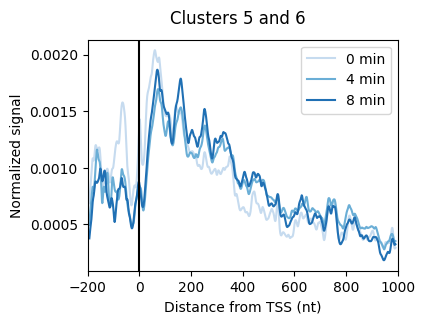

In [63]:
mp_nab3 = pd.DataFrame({
    '0 min': mp00[['Nab3_wt_0min_1', 'Nab3_wt_0min_2']].mean(axis=1),
    '4 min': mp00['Nab3_wt_4min_1'],
    '8 min': mp00[['Nab3_wt_8min_1', 'Nab3_wt_8min_2']].mean(axis=1),
})
fig, ax = plt.subplots(figsize=(4, 3))
sns.lineplot(
    data=mp_nab3.rolling(window=15, center=True, win_type='blackman').mean(),
    dashes=False,
    palette='Blues', ax=ax
)
ax.set_xlim(-200, 1000)
ax.axvline(0, color='k')
ax.set_xlabel('Distance from TSS (nt)')
ax.set_ylabel('Normalized signal')
fig.suptitle('Clusters 5 and 6')

This seems to work OK, results look a bit different, probably because we're not aligning to TSS but start codon.

TODO: include UTRs in BED

## Fig. 3D

### Nab3

Find strongest crosslink site for each transcript based on microdeletions at 0 min

In [45]:
bw_nab3_del_plus = sorted([
    bw_folder+file for file
    in os.listdir(bw_folder)
    if file.endswith("_PROFILE_del0_fwd.bw")
    and "Nab3" in file
    and "0min" in file
])
bw_nab3_del_minus = sorted([
    bw_folder+file for file
    in os.listdir(bw_folder)
    if file.endswith("_PROFILE_del0_rev.bw")
    and "Nab3" in file
    and "0min" in file
])
mm_nab3_del = meta.getMultipleMatrices(
    bw_nab3_del_plus, bw_nab3_del_minus, bed_fig3,
    flank_5=0, flank_3=0
)

Aggregate accross samples

In [46]:
mm_nab3_del_concat = pd.concat(mm_nab3_del.values(), keys=range(len(mm_nab3_del)))

mm_nab3_del_agg = {
    "sum": mm_nab3_del_concat.groupby(level=1).sum(),
    "mean": mm_nab3_del_concat.groupby(level=1).mean(),
    "median": mm_nab3_del_concat.groupby(level=1).median(),
}

mm_nab3_del_agg_max = {
    "sum": mm_nab3_del_agg["sum"].idxmax(axis=1),
    "mean": mm_nab3_del_agg["mean"].idxmax(axis=1),
    "median": mm_nab3_del_agg["median"].idxmax(axis=1),
}
mm_nab3_del_agg_max_df = pd.DataFrame(mm_nab3_del_agg_max)
mm_nab3_del_agg_max_df

,sum,mean,median
ABP1,82,82,82
ADH6,1097,1097,1097
ALO1,28,28,28
APL1,228,228,228
APM4,799,799,799
...,...,...,...
YPK9,1709,1709,1709
YRF1-2,263,263,263
YRF1-3,379,379,0
YRF1-5,259,259,259


Go with mean

Use these offsets to construct a new BED with crosslink locations

In [47]:
def del_offset_to_bed(offset_df, bed_df):
    offset_df = offset_df.copy()
    offset_df['gene_name'] = offset_df.index
    bed_df = bed_df.copy()
    bed_df['gene_name'] = bed_df[3]
    merged_df = pd.merge(offset_df, bed_df, on='gene_name', how='left')
    merged_df['new_start'] = 0
    merged_df['new_end'] = 0
    for index, row in merged_df.iterrows():
        if row[5] == '+':
            merged_df.at[index, 'new_start'] = row[1] + row['mean'] + 1
            merged_df.at[index, 'new_end'] = row[1] + row['mean'] + 2
        elif row[5] == '-':
            merged_df.at[index, 'new_start'] = row[2] - row['mean'] - 1
            merged_df.at[index, 'new_end'] = row[2] - row['mean']
    return merged_df[[0, 'new_start', 'new_end', 'gene_name', 4, 5]]

In [48]:
bed_fig3_nab3_del = del_offset_to_bed(mm_nab3_del_agg_max_df[['mean']], bed_fig3)
mp_fig3_nab_del = meta.metaprofile(
    meta.getMultipleMatrices(
        bw_plus, bw_minus, bed_fig3_nab3_del,
        flank_5=400, flank_3=400
    ),
    normalize_internal=True
)
mp_fig3_nab_del = cleanNames(mp_fig3_nab_del, ['../04a_BigWig_umitools/SB060916_', '_all_umitools_CPM_fwd.bw'])
mp_fig3_nab_del
mp_fig3_nab_del['0 min'] = mp_fig3_nab_del[['Nab3_wt_0min_1', 'Nab3_wt_0min_2']].mean(axis=1)
mp_fig3_nab_del['4 min'] = mp_fig3_nab_del['Nab3_wt_4min_1']

Text(0.5, 0.98, 'Nab3')

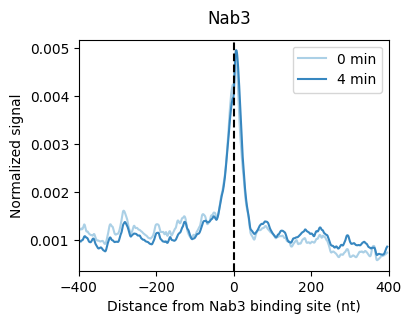

In [64]:
plotdata = mp_fig3_nab_del[['0 min', '4 min']].rolling(window=10, center=True, win_type='blackman').mean()
fig, ax = plt.subplots(figsize=(4, 3))
sns.lineplot(
    data=plotdata,
    dashes=False,
    palette='Blues', ax=ax
)
ax.set_xlim(-400, 400)
ax.axvline(0, color='k', linestyle='--')
ax.set_xlabel('Distance from Nab3 binding site (nt)')
ax.set_ylabel('Normalized signal')
plt.suptitle("Nab3")

### Mtr4

In [50]:
bw_mtr4_del_plus = sorted([
    bw_folder + file
    for file in os.listdir(bw_folder)
    if file.endswith("_PROFILE_del0_fwd.bw")
    and "Mtr4" in file
    and "0min" in file
    and "mock" not in file
])

bw_mtr4_del_minus = sorted([
    bw_folder + file
    for file in os.listdir(bw_folder)
    if file.endswith("_PROFILE_del0_rev.bw")
    and "Mtr4" in file
    and "0min" in file
    and "mock" not in file
])

In [51]:
mm_mtr4_del = meta.getMultipleMatrices(
    bw_mtr4_del_plus,
    bw_mtr4_del_minus,
    bed_fig3,
    flank_5=0,
    flank_3=0,
)

mm_mtr4_del_concat = pd.concat(
    mm_mtr4_del.values(),
    keys=range(len(mm_mtr4_del)),
)

mm_mtr4_del_agg = {
    "sum": mm_mtr4_del_concat.groupby(level=1).sum(),
    "mean": mm_mtr4_del_concat.groupby(level=1).mean(),
    "median": mm_mtr4_del_concat.groupby(level=1).median(),
}

mm_mtr4_del_agg_max_df = pd.DataFrame({
    key: value.idxmax(axis=1)
    for key, value in mm_mtr4_del_agg.items()
})

mm_mtr4_del_agg_max_df

,sum,mean,median
ABP1,278,278,278
ADH6,165,165,165
ALO1,0,0,0
APL1,151,151,151
APM4,0,0,0
...,...,...,...
YPK9,343,343,343
YRF1-2,1447,1447,1447
YRF1-3,3,3,0
YRF1-5,786,786,786


In [57]:
bed_fig3_mtr4_del = del_offset_to_bed(
    mm_mtr4_del_agg_max_df[["mean"]],
    bed_fig3,
)

mp_fig3_mtr4_del = meta.metaprofile(
    meta.getMultipleMatrices(
        bw_plus,
        bw_minus,
        # bed_fig3_mtr4_del,
        bed_fig3_nab3_del,
        flank_5=400,
        flank_3=400,
    ),
    normalize_internal=True,
)

mp_fig3_mtr4_del = cleanNames(
    mp_fig3_mtr4_del,
    [
        "../04a_BigWig_umitools/SB060916_",
        "_all_umitools_CPM_fwd.bw",
    ],
)

mp_fig3_mtr4_del["0 min"] = mp_fig3_mtr4_del[
    ["Mtr4_wt_0min_1", "Mtr4_wt_0min_2"]
].mean(axis=1)

mp_fig3_mtr4_del["4 min"] = mp_fig3_mtr4_del["Mtr4_wt_4min_1"]

Text(0.5, 0.98, 'Mtr4')

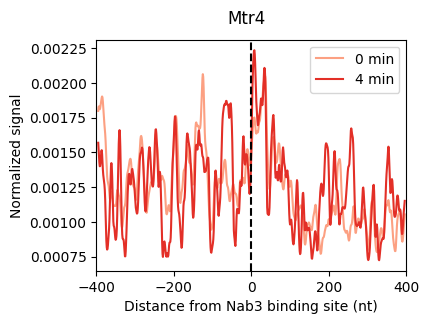

In [65]:
plotdata = mp_fig3_mtr4_del[["0 min", "4 min"]].rolling(
    window=10,
    center=True,
    win_type="blackman",
).mean()

fig, ax = plt.subplots(figsize=(4, 3))

sns.lineplot(
    data=plotdata,
    dashes=False,
    palette="Reds",
    ax=ax,
)
ax.set_xlim(-400, 400)
ax.axvline(0, color="k", linestyle="--")
ax.set_xlabel('Distance from Nab3 binding site (nt)')
ax.set_ylabel('Normalized signal')
plt.suptitle("Mtr4")